<a href="https://colab.research.google.com/github/Palak-mukheja/LeetCode/blob/main/UNC503_A1_1024150040_Palak.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNC503 AIML Laboratory | Assignment 1
## Python Essentials through a Command-Driven Campus Robot

| | |
|---|---|
| **Name** | Palak Mukheja |
| **Roll No** | `1024150040` |
| **Institute** | Thapar Institute of Engineering and Technology, Patiala |
| **Course** | UNC503 - Artificial Intelligence and Machine Learning Laboratory |
| **Robot ID used** | RB-104 |

### Objective and problem restatement
A delivery robot on a campus grid receives a **human-supplied list of commands** (NORTH, SOUTH, EAST, WEST, WAIT).
My Python program must **clean** the text, **validate** the robot ID and the grid, **execute** the commands one at a time,
**record** a step-by-step log, **calculate** the terrain cost of valid moves, and **report** whether the goal `G` was reached.
The robot does **not** choose its own route here; automatic route selection is Assignment 2.

**How to run:** `Runtime -> Restart session and run all` (Colab) or `Restart` then `Run All` (VS Code Jupyter). Only the standard library, NumPy, pandas and Matplotlib are used.

## 0. Imports and supplied constants
*Why:* Everything the program needs is defined once, at the top, so every later function reads the same data.
`RECOGNISED_COMMANDS` is my own helper constant: a **set** (fast membership test) built from the four movement keys plus `WAIT`.

In [45]:
import numpy as np                      # used only to turn the grid into a numeric array for plotting
import pandas as pd                     # comparison table
import matplotlib.pyplot as plt         # trajectory plots
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ---- supplied constants (Task 1A) ----
GRID = [
    ['S', '.', '.', '#', '.'],
    ['.', 'M', '.', '.', '.'],
    ['#', '.', 'C', '#', '.'],
    ['.', '.', '.', '.', 'G'],
]

MOVE_DELTAS = {
    'NORTH': (-1, 0),
    'SOUTH': ( 1, 0),
    'WEST':  ( 0,-1),
    'EAST':  ( 0, 1),
}

TERRAIN_COSTS = {'S': 0, 'G': 1, '.': 1, 'M': 3, 'C': 2}

ALLOWED_SYMBOLS = {'S', 'G', '.', 'M', 'C', '#'}          # set: unique symbols, fast "is this allowed?" check
RECOGNISED_COMMANDS = set(MOVE_DELTAS) | {'WAIT'}          # helper set: every command the robot understands

## Task 1 - Understand and construct the data model
**1A** is done above (GRID, MOVE_DELTAS, TERRAIN_COSTS, ALLOWED_SYMBOLS).

**1B** - the robot's record is a dictionary because each value has a *name* (`robot_id`, `battery`, ...) and we want to look values up by name, not by index.

In [46]:
# Task 1B
robot_record = {
    'robot_id': 'RB-104',
    'position': (0, 0),
    'battery': 80,
    'goal_reached': False,
    'total_cost': 0,
}
print(robot_record)

# Evidence for 1C: ask Python itself for the types
total_cost = robot_record['total_cost']
for label, obj in [('GRID', GRID), ('GRID[0]', GRID[0]), ('(0, 0)', (0, 0)),
                   ('MOVE_DELTAS', MOVE_DELTAS), ('ALLOWED_SYMBOLS', ALLOWED_SYMBOLS),
                   ('total_cost', total_cost)]:
    print(f'{label:16} -> {type(obj).__name__}')

{'robot_id': 'RB-104', 'position': (0, 0), 'battery': 80, 'goal_reached': False, 'total_cost': 0}
GRID             -> list
GRID[0]          -> list
(0, 0)           -> tuple
MOVE_DELTAS      -> dict
ALLOWED_SYMBOLS  -> set
total_cost       -> int


**1C - Types and why they suit the job**

| Object | Python type | Why this type is suitable |
|---|---|---|
| `GRID` | `list` (of lists) | An ordered 2-D table that we index as `GRID[row][col]`; rows stay in a fixed order. |
| `GRID[0]` | `list` | One row of the map: an ordered sequence of cells we can loop over. |
| `(0, 0)` | `tuple` | A coordinate is a fixed pair `(row, col)`; being immutable and hashable it can sit in sets and be a dictionary key. |
| `MOVE_DELTAS` | `dict` | Maps a command string directly to its movement tuple, so no chain of `if/elif` is needed. |
| `ALLOWED_SYMBOLS` | `set` | Only uniqueness and a quick "is this symbol allowed?" test matter; order does not. |
| `total_cost` | `int` | A running whole-number sum of terrain costs that we add to. |

In [47]:
# Task 1D - tuple unpacking
position = (2, 4)
row, col = position
print('row    =', row)
print('column =', col)

row    = 2
column = 4


## Task 2 - Clean and validate text input
Raw text from a human is messy (extra spaces, lower case, empty entries). Cleaning it **first** means every later function can assume tidy input.

**2A** `validate_robot_id`: normalise with `strip()` + `upper()`, then check length 6, prefix `RB-` (slicing) and three digits.

In [48]:
def validate_robot_id(robot_id):
    """Return True if robot_id is 'RB-' followed by exactly three digits (after strip + upper)."""
    if not isinstance(robot_id, str):                 # numbers, None, etc. cannot be valid IDs
        return False
    rid = robot_id.strip().upper()
    prefix, digits = rid[:3], rid[3:]                 # slicing: 'RB-' and the remaining characters
    return len(rid) == 6 and prefix == 'RB-' and digits.isdigit() and digits.isascii()


for test, expected in [('RB-104', True), (' rb-104 ', True),
                       ('RB104', False), ('R-104', False), ('RB-10A', False), ('RB-1045', False)]:
    print(f'{test!r:12} -> {validate_robot_id(test)}  (expected {expected})')

'RB-104'     -> True  (expected True)
' rb-104 '   -> True  (expected True)
'RB104'      -> False  (expected False)
'R-104'      -> False  (expected False)
'RB-10A'     -> False  (expected False)
'RB-1045'    -> False  (expected False)


**2B** `clean_commands`: split on commas, `strip()`, `upper()`, and throw away *empty* entries only. Non-empty unknown words such as `JUMP` are kept.

**2D policy (stated):** if the input is **not a string**, `clean_commands` **raises a `TypeError`** with a clear message. Reason: silently returning `[]` would hide a programming mistake (e.g. passing a list or `None`), whereas an explicit error is easy to spot and fix.

In [49]:
def clean_commands(raw_text):
    """
    Turn 'south, EAST, , wait' into ['SOUTH', 'EAST', 'WAIT'].
    Policy for non-string input: raise TypeError (documented, consistent).
    """
    if not isinstance(raw_text, str):
        raise TypeError(f'clean_commands expects a string, got {type(raw_text).__name__}')
    pieces = [piece.strip().upper() for piece in raw_text.split(',')]
    return [piece for piece in pieces if piece]       # keep every non-empty entry, even unknown ones


raw = ' south, EAST, , wait, jump, north '            # supplied test
expected = ['SOUTH', 'EAST', 'WAIT', 'JUMP', 'NORTH']
print(clean_commands(raw))
print('matches expected:', clean_commands(raw) == expected)

['SOUTH', 'EAST', 'WAIT', 'JUMP', 'NORTH']
matches expected: True


**2C - Why keep `JUMP`?**
`clean_commands` is only responsible for *tidying* text, not for deciding what the robot understands. If it deleted `JUMP`, the simulator would never learn that the operator sent a bad command, so it could not log `UNKNOWN_COMMAND` or increase `unknown_commands`.

In [50]:
# Task 2D - edge-case tests
print('empty string        ->', clean_commands(''))
print('only commas/spaces  ->', clean_commands(' , ,,  , '))
for bad in [None, 42, ['EAST', 'WEST']]:
    try:
        clean_commands(bad)
    except TypeError as err:
        print(f'{bad!r:20} -> TypeError: {err}')

empty string        -> []
only commas/spaces  -> []
None                 -> TypeError: clean_commands expects a string, got NoneType
42                   -> TypeError: clean_commands expects a string, got int
['EAST', 'WEST']     -> TypeError: clean_commands expects a string, got list


## Task 3 - Summarise commands and decide mission readiness
**3A** `command_summary` loops over the commands to build a **frequencies dictionary**, uses **list comprehensions** to pick out known and movement commands, and a **set** for unique commands.

In [51]:
def command_summary(commands):
    """Count total/known/unknown/movement/WAIT commands, frequencies (dict) and unique commands (set)."""
    frequencies = {}
    for command in commands:                                      # normal loop: counting into a dictionary
        frequencies[command] = frequencies.get(command, 0) + 1

    known = [c for c in commands if c in RECOGNISED_COMMANDS]     # comprehension (3D)
    movement = [c for c in commands if c in MOVE_DELTAS]          # comprehension (3D)

    return {
        'total_commands': len(commands),
        'known_commands': len(known),
        'unknown_commands': len(commands) - len(known),
        'movement_commands': len(movement),
        'wait_commands': frequencies.get('WAIT', 0),
        'frequencies': frequencies,
        'unique_commands': set(commands),
    }


summary_demo = command_summary(['EAST', 'EAST', 'WAIT', 'JUMP', 'SOUTH'])
for key, value in summary_demo.items():
    print(f'{key:18}: {value}')

total_commands    : 5
known_commands    : 4
unknown_commands  : 1
movement_commands : 3
wait_commands     : 1
frequencies       : {'EAST': 2, 'WAIT': 1, 'JUMP': 1, 'SOUTH': 1}
unique_commands   : {'JUMP', 'SOUTH', 'WAIT', 'EAST'}


**3B** `mission_ready` uses Boolean logic: battery must be a real number (not `True/False`) from 25 to 100 **and** the grid must be valid **and** there must be at least one command.

In [52]:
def mission_ready(battery, grid_valid, commands):
    """True only if battery is a number in [25, 100], grid_valid is True and commands is not empty."""
    is_number = isinstance(battery, (int, float)) and not isinstance(battery, bool)
    battery_ok = is_number and 25 <= battery <= 100
    has_commands = commands is not None and len(commands) > 0
    return battery_ok and (grid_valid is True) and has_commands


print(mission_ready(80, True, ['EAST']))     # True
print(mission_ready(25, True, ['EAST']))     # True  (boundary)
print(mission_ready(24, True, ['EAST']))     # False (below boundary)
print(mission_ready(80, False, ['EAST']))    # False (bad grid)
print(mission_ready(80, True, []))           # False (nothing to do)

True
True
False
False
False


**3C - and / or / not in a meaningful expression**

In [53]:
# 3C: a pre-flight "needs attention" flag that uses all three Boolean operators
battery, grid_valid, commands = 20, True, ['EAST', 'JUMP']
has_unknown = any(c not in RECOGNISED_COMMANDS for c in commands)          # `not` inside a test
needs_attention = (not grid_valid) or (battery < 25) or has_unknown        # `not`, `or`
safe_to_launch = grid_valid and battery >= 25 and not has_unknown          # `and`, `not`
print('needs_attention:', needs_attention, '| safe_to_launch:', safe_to_launch)

needs_attention: True | safe_to_launch: False


**Plain-language explanation.** `needs_attention` is `True` if **any one** problem exists: the grid is *not* valid, **or** the battery is below 25, **or** an unknown command is present (`or` = at least one is true).
`safe_to_launch` is the opposite situation: it needs the grid valid **and** the battery high enough **and** *not* having an unknown command (`and` = all must be true). Here battery is 20 and `JUMP` is unknown, so the robot needs attention and is not safe to launch. The same `and`/`not` idea is used inside `mission_ready` and `validate_robot_id`.

**3D - Why the comprehensions stay readable.** Each one is a single line with a clear filter, e.g. `[c for c in commands if c in MOVE_DELTAS]` reads almost like English: "every command *c* in commands that is a movement key". They do one simple job (filtering), so no nested loops or complex conditions are hidden inside.

In [54]:
# 3D - one more readable comprehension: a dict comprehension that isolates the unknown commands
unknown_only = {cmd: n for cmd, n in summary_demo['frequencies'].items() if cmd not in RECOGNISED_COMMANDS}
print(unknown_only)

{'JUMP': 1}


## Task 4 - Validate the campus grid
The simulator must never run on a broken map, so the grid is checked first. `validate_grid` **collects every applicable error** instead of stopping at the first one.

Error codes: `EMPTY_GRID`, `NON_RECTANGULAR`, `INVALID_SYMBOL`, `START_COUNT`, `GOAL_COUNT`.
If the grid is empty nothing else can be checked safely, so only `EMPTY_GRID` is reported in that case.

In [55]:
def validate_grid(grid):
    """Return {'valid': bool, 'errors': list_of_error_codes}. Reports all checkable errors."""
    errors = []

    # 1) at least one non-empty row
    if not grid or all(len(row) == 0 for row in grid):
        return {'valid': False, 'errors': ['EMPTY_GRID']}

    # 2) rectangular: every row has the same length (a set of lengths must have size 1)
    if len({len(row) for row in grid}) > 1:
        errors.append('NON_RECTANGULAR')

    # 3) allowed symbols and 4) counts of S and G (nested loops + counters)
    start_count = 0
    goal_count = 0
    bad_symbol_found = False
    for row in grid:
        for cell in row:
            if cell not in ALLOWED_SYMBOLS:
                bad_symbol_found = True
            elif cell == 'S':
                start_count += 1
            elif cell == 'G':
                goal_count += 1

    if bad_symbol_found:
        errors.append('INVALID_SYMBOL')
    if start_count != 1:
        errors.append('START_COUNT')
    if goal_count != 1:
        errors.append('GOAL_COUNT')

    return {'valid': len(errors) == 0, 'errors': errors}


def find_symbol(grid, symbol):
    """Return (row, col) only if `symbol` occurs exactly once, else None."""
    matches = []
    for r, row in enumerate(grid):
        for c, cell in enumerate(row):
            if cell == symbol:
                matches.append((r, c))
    return matches[0] if len(matches) == 1 else None


def inside_grid(grid, position):
    """True if position=(row, col) is inside the grid. Negative indices are rejected explicitly."""
    row, col = position
    if row < 0 or col < 0:                       # Python would silently wrap negatives, so we block them
        return False
    return row < len(grid) and col < len(grid[row])


print('S ->', find_symbol(GRID, 'S'), '| G ->', find_symbol(GRID, 'G'), '| # (appears 3x) ->', find_symbol(GRID, '#'))
print('inside (0,0):', inside_grid(GRID, (0, 0)), '| inside (-1,0):', inside_grid(GRID, (-1, 0)),
      '| inside (4,0):', inside_grid(GRID, (4, 0)), '| inside (0,5):', inside_grid(GRID, (0, 5)))

S -> (0, 0) | G -> (3, 4) | # (appears 3x) -> None
inside (0,0): True | inside (-1,0): False | inside (4,0): False | inside (0,5): False


**4D - Test the supplied grid and five invalid grids** (missing G, two S, unequal row lengths, unknown symbol, empty).

In [56]:
grid_missing_goal = [['S', '.'], ['.', '.']]
grid_two_starts   = [['S', '.'], ['S', 'G']]
grid_unequal      = [['S', '.', '.'], ['.', 'G']]
grid_bad_symbol   = [['S', 'X'], ['.', 'G']]
grid_empty        = []

tests = {
    'supplied GRID': GRID,
    'missing G': grid_missing_goal,
    'two S cells': grid_two_starts,
    'unequal rows': grid_unequal,
    'unknown symbol': grid_bad_symbol,
    'empty grid': grid_empty,
}
for name, g in tests.items():
    print(f'{name:15} -> {validate_grid(g)}')

supplied GRID   -> {'valid': True, 'errors': []}
missing G       -> {'valid': False, 'errors': ['GOAL_COUNT']}
two S cells     -> {'valid': False, 'errors': ['START_COUNT']}
unequal rows    -> {'valid': False, 'errors': ['NON_RECTANGULAR']}
unknown symbol  -> {'valid': False, 'errors': ['INVALID_SYMBOL']}
empty grid      -> {'valid': False, 'errors': ['EMPTY_GRID']}


## Worked trace - "Check your understanding" (before Task 5)
Original third command: `EAST` from (0, 2) hits `#` at (0, 3), so status `BLOCKED_OBSTACLE`, position stays (0, 2), step cost 0, total 2.

**If the third command were `WAIT` instead:**

| Status | Position | Step cost | Total cost |
|---|---|---|---|
| `WAITED` | (0, 2) (unchanged) | 0 | 2 |

The robot still stays at (0, 2) and the cost is still 0, but the *reason* differs: WAIT is a deliberate, recognised command, so it increases `waits`, not `blocked_moves`. The next `SOUTH` still goes to (1, 2) and total becomes 3. (This is verified with code after Task 6.)

## Task 5 - Implement one command at a time
`move_once` is the **transition rule**: current state + action -> new state, status and cost. It never edits the grid (5C); it only *reports*.

Decision order (early returns keep the code flat and clear):
1. `WAIT` -> `WAITED`
2. not in `MOVE_DELTAS` -> `UNKNOWN_COMMAND`
3. candidate = position + delta (tuple arithmetic, 5B)
4. outside grid -> `BLOCKED_BOUNDARY`
5. cell is `#` -> `BLOCKED_OBSTACLE`
6. otherwise `MOVED`, cost = `TERRAIN_COSTS[destination symbol]`

In [57]:
def move_once(grid, position, command):
    """Apply ONE command. Returns {'new_position', 'status', 'step_cost'}. Never modifies `grid`."""
    if command == 'WAIT':
        return {'new_position': position, 'status': 'WAITED', 'step_cost': 0}

    if command not in MOVE_DELTAS:
        return {'new_position': position, 'status': 'UNKNOWN_COMMAND', 'step_cost': 0}

    d_row, d_col = MOVE_DELTAS[command]                         # dictionary lookup -> tuple
    row, col = position                                         # tuple unpacking
    candidate_row, candidate_col = row + d_row, col + d_col     # 5B: arithmetic on the tuples
    candidate = (candidate_row, candidate_col)

    if not inside_grid(grid, candidate):
        return {'new_position': position, 'status': 'BLOCKED_BOUNDARY', 'step_cost': 0}

    destination = grid[candidate_row][candidate_col]
    if destination == '#':
        return {'new_position': position, 'status': 'BLOCKED_OBSTACLE', 'step_cost': 0}

    return {'new_position': candidate, 'status': 'MOVED', 'step_cost': TERRAIN_COSTS[destination]}


# 5D - the five required one-step tests (printed here, asserted again in Task 8)
for pos, cmd in [((0, 0), 'EAST'), ((0, 0), 'NORTH'), ((0, 2), 'EAST'), ((1, 1), 'WAIT'), ((1, 1), 'JUMP')]:
    print(f'move_once(GRID, {pos}, {cmd!r:7}) -> {move_once(GRID, pos, cmd)}')

move_once(GRID, (0, 0), 'EAST' ) -> {'new_position': (0, 1), 'status': 'MOVED', 'step_cost': 1}
move_once(GRID, (0, 0), 'NORTH') -> {'new_position': (0, 0), 'status': 'BLOCKED_BOUNDARY', 'step_cost': 0}
move_once(GRID, (0, 2), 'EAST' ) -> {'new_position': (0, 2), 'status': 'BLOCKED_OBSTACLE', 'step_cost': 0}
move_once(GRID, (1, 1), 'WAIT' ) -> {'new_position': (1, 1), 'status': 'WAITED', 'step_cost': 0}
move_once(GRID, (1, 1), 'JUMP' ) -> {'new_position': (1, 1), 'status': 'UNKNOWN_COMMAND', 'step_cost': 0}


## Task 6 - Build the complete command simulator
`simulate_commands` is mostly **orchestration**: it *reuses* `validate_robot_id`, `validate_grid`, `find_symbol` and `move_once` rather than repeating boundary/obstacle logic.

Flow: validate ID -> validate grid (stop if bad) -> find S and G -> loop over commands, calling `move_once` once each -> update position, cost and **exactly one** counter -> append to `history` and `log` -> stop right after the goal is reached.

In [58]:
def _failed_result(status, robot_id, commands, errors):
    """Result with all required keys for a simulation that never started."""
    return {
        'simulation_status': status,
        'robot_id': robot_id,
        'start_position': None,
        'final_position': None,
        'goal_reached': False,
        'commands_received': len(commands),
        'commands_processed': 0,
        'valid_moves': 0,
        'waits': 0,
        'blocked_moves': 0,
        'unknown_commands': 0,
        'total_cost': 0,
        'history': [],
        'unique_positions': set(),
        'log': [],
        'errors': list(errors),
    }


def simulate_commands(grid, commands, robot_id):
    """Run a full mission and return the required result dictionary."""
    if isinstance(commands, str):                     # convenience: accept raw text too
        commands = clean_commands(commands)
    commands = list(commands)

    # 1) robot ID
    if not validate_robot_id(robot_id):
        return _failed_result('INVALID_ROBOT_ID', robot_id, commands, ['INVALID_ROBOT_ID'])
    clean_id = robot_id.strip().upper()

    # 2) grid - do not move on a bad grid
    check = validate_grid(grid)
    if not check['valid']:
        return _failed_result('INVALID_GRID', clean_id, commands, check['errors'])

    # 3) initial state
    start = find_symbol(grid, 'S')
    goal = find_symbol(grid, 'G')
    position = start
    history = [start]
    log = []
    valid_moves = waits = blocked_moves = unknown_commands = 0
    total_cost = 0

    # 4) process commands
    for step, command in enumerate(commands, start=1):
        from_position = position
        outcome = move_once(grid, position, command)
        position = outcome['new_position']
        total_cost += outcome['step_cost']
        status = outcome['status']

        if status == 'MOVED':                                   # exactly one counter per command
            valid_moves += 1
        elif status == 'WAITED':
            waits += 1
        elif status in ('BLOCKED_BOUNDARY', 'BLOCKED_OBSTACLE'):
            blocked_moves += 1
        else:                                                   # UNKNOWN_COMMAND
            unknown_commands += 1

        history.append(position)                                # recorded even when position did not change
        log.append({
            'step': step,
            'command': command,
            'from_position': from_position,
            'to_position': position,
            'status': status,
            'step_cost': outcome['step_cost'],
            'cumulative_cost': total_cost,
        })

        if status == 'MOVED' and position == goal:              # goal test -> stop immediately
            break

    return {
        'simulation_status': 'COMPLETED',
        'robot_id': clean_id,
        'start_position': start,
        'final_position': position,
        'goal_reached': position == goal,
        'commands_received': len(commands),
        'commands_processed': len(log),
        'valid_moves': valid_moves,
        'waits': waits,
        'blocked_moves': blocked_moves,
        'unknown_commands': unknown_commands,
        'total_cost': total_cost,
        'history': history,
        'unique_positions': set(history),
        'log': log,
        'errors': [],
        'goal_position': goal,                                  # extra (allowed) field
    }

In [59]:
# Reproduce the worked trace from section 4.1 and the WAIT variant
trace = simulate_commands(GRID, ['EAST', 'EAST', 'EAST', 'SOUTH'], 'RB-104')
print('Worked trace (3rd EAST blocked):')
print(pd.DataFrame(trace['log']).to_string(index=False))
print('total cost:', trace['total_cost'], '\n')

wait_variant = simulate_commands(GRID, ['EAST', 'EAST', 'WAIT', 'SOUTH'], 'RB-104')
print('Variant with WAIT as 3rd command:')
print(pd.DataFrame(wait_variant['log']).to_string(index=False))
print('waits:', wait_variant['waits'], '| blocked_moves:', wait_variant['blocked_moves'], '| total cost:', wait_variant['total_cost'])

# Invalid inputs are rejected without moving
print('\nbad grid  ->', simulate_commands(grid_missing_goal, ['EAST'], 'RB-104')['simulation_status'],
      simulate_commands(grid_missing_goal, ['EAST'], 'RB-104')['errors'])
print('bad ID    ->', simulate_commands(GRID, ['EAST'], 'RB104')['simulation_status'])

Worked trace (3rd EAST blocked):
 step command from_position to_position           status  step_cost  cumulative_cost
    1    EAST        (0, 0)      (0, 1)            MOVED          1                1
    2    EAST        (0, 1)      (0, 2)            MOVED          1                2
    3    EAST        (0, 2)      (0, 2) BLOCKED_OBSTACLE          0                2
    4   SOUTH        (0, 2)      (1, 2)            MOVED          1                3
total cost: 3 

Variant with WAIT as 3rd command:
 step command from_position to_position status  step_cost  cumulative_cost
    1    EAST        (0, 0)      (0, 1)  MOVED          1                1
    2    EAST        (0, 1)      (0, 2)  MOVED          1                2
    3    WAIT        (0, 2)      (0, 2) WAITED          0                2
    4   SOUTH        (0, 2)      (1, 2)  MOVED          1                3
waits: 1 | blocked_moves: 0 | total cost: 3

bad grid  -> INVALID_GRID ['GOAL_COUNT']
bad ID    -> INVALID_ROBOT_ID


## Task 7 - Compare routes and display the trajectory
**7A** - Run A, B, C and design **Sequence D**.

*Design of D:* it needs a `WAIT`, a blocked attempt, and must still reach G. I start with `WAIT`, then `NORTH` from (0, 0) (a boundary block), then take a route that avoids both the muddy cell `M` (cost 3) and the crowded cell `C` (cost 2): along the top row to (0, 2), down to (1, 2), right along row 1 to (1, 4), then down to G. Every entered cell is a normal path, so cost equals the 7 moves needed.

In [60]:
SEQUENCE_A = ['SOUTH', 'EAST', 'EAST', 'EAST', 'EAST', 'SOUTH', 'SOUTH']
SEQUENCE_B = ['EAST', 'EAST', 'SOUTH', 'SOUTH', 'SOUTH', 'EAST', 'EAST']
SEQUENCE_C = ['NORTH', 'EAST', 'EAST', 'EAST', 'SOUTH',
              'JUMP', 'SOUTH', 'SOUTH', 'EAST', 'EAST']
SEQUENCE_D = ['WAIT', 'NORTH', 'EAST', 'EAST', 'SOUTH', 'EAST', 'EAST', 'SOUTH', 'SOUTH']   # my design

SEQUENCES = {'A': SEQUENCE_A, 'B': SEQUENCE_B, 'C': SEQUENCE_C, 'D': SEQUENCE_D}
results = {name: simulate_commands(GRID, seq, 'RB-104') for name, seq in SEQUENCES.items()}

for name, res in results.items():
    print(f"Sequence {name}: goal={res['goal_reached']}, final={res['final_position']}, "
          f"cost={res['total_cost']}, valid={res['valid_moves']}, blocked={res['blocked_moves']}, "
          f"unknown={res['unknown_commands']}, waits={res['waits']}")

Sequence A: goal=True, final=(3, 4), cost=9, valid=7, blocked=0, unknown=0, waits=0
Sequence B: goal=True, final=(3, 4), cost=8, valid=7, blocked=0, unknown=0, waits=0
Sequence C: goal=True, final=(3, 4), cost=8, valid=7, blocked=2, unknown=1, waits=0
Sequence D: goal=True, final=(3, 4), cost=7, valid=7, blocked=1, unknown=0, waits=1


**7B** - The comparison table is **built from the simulator output** (no manually typed numbers).

In [61]:
columns = ['commands_received', 'commands_processed', 'valid_moves', 'waits', 'blocked_moves',
           'unknown_commands', 'total_cost']

rows = []
for name, res in results.items():
    row = {col: res[col] for col in columns}
    row['unique_positions_count'] = len(res['unique_positions'])
    row['goal_reached'] = res['goal_reached']
    rows.append(row)

comparison = pd.DataFrame(rows, index=[f'Sequence {n}' for n in results])
comparison

,commands_received,commands_processed,valid_moves,waits,blocked_moves,unknown_commands,total_cost,unique_positions_count,goal_reached
Sequence A,7,7,7,0,0,0,9,8,True
Sequence B,7,7,7,0,0,0,8,8,True
Sequence C,10,10,7,0,2,1,8,8,True
Sequence D,9,9,7,1,1,0,7,8,True


**7C** - `plot_trajectory` draws the terrain as coloured cells (each cell also shows its symbol), overlays the recorded `history` in processing order as a line with markers, and writes the **step indices** at each visited cell (so a robot that stays still shows several numbers on one cell). Axes are labelled *row* and *column*; row 0 is at the top, matching the grid.

In [62]:
def plot_trajectory(grid, result, title, ax=None):
    """Draw terrain + the robot's recorded history. Returns (fig, ax)."""
    codes = {'.': 0, 'M': 1, 'C': 2, '#': 3, 'S': 4, 'G': 5}
    colours = ['#f4f4f4', '#a67c52', '#f5b041', '#2c3e50', '#58d68d', '#f7dc6f']
    names = ['Normal (.)', 'Muddy (M)', 'Crowded (C)', 'Obstacle (#)', 'Start (S)', 'Goal (G)']

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4.5))
    else:
        fig = ax.figure

    data = np.array([[codes[cell] for cell in row] for row in grid])
    ax.imshow(data, cmap=ListedColormap(colours), vmin=-0.5, vmax=5.5)

    # symbol in each cell
    for r, row in enumerate(grid):
        for c, cell in enumerate(row):
            ax.text(c, r, cell, ha='center', va='center',
                    color='white' if cell == '#' else 'black', fontsize=12, alpha=0.55)

    # trajectory overlay, in processing order
    history = result['history']
    if history:
        xs = [c for r, c in history]
        ys = [r for r, c in history]
        ax.plot(xs, ys, '-o', color='crimson', linewidth=2, markersize=6, zorder=3)

        visits = {}                                  # position -> list of history indices
        for index, pos in enumerate(history):
            visits.setdefault(pos, []).append(index)
        for (r, c), indices in visits.items():
            ax.annotate(','.join(str(i) for i in indices), (c, r), xytext=(4, -10),
                        textcoords='offset points', fontsize=8, color='navy', zorder=4,
                        fontweight='bold')

    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticks([x - 0.5 for x in range(len(grid[0]) + 1)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(len(grid) + 1)], minor=True)
    ax.grid(which='minor', color='grey', linewidth=0.8)
    ax.tick_params(which='minor', length=0)
    ax.set_xlabel('column')
    ax.set_ylabel('row')
    ax.set_title(title, fontsize=10)

    handles = [Patch(facecolor=col, edgecolor='grey', label=lab) for col, lab in zip(colours, names)]
    handles.append(Line2D([0], [0], color='crimson', marker='o', label='Path (numbers = step index)'))
    ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=7)
    return fig, ax

**7D** - 1 x 2 subplot for Sequence B and Sequence D. Titles include sequence name, total cost and goal status.

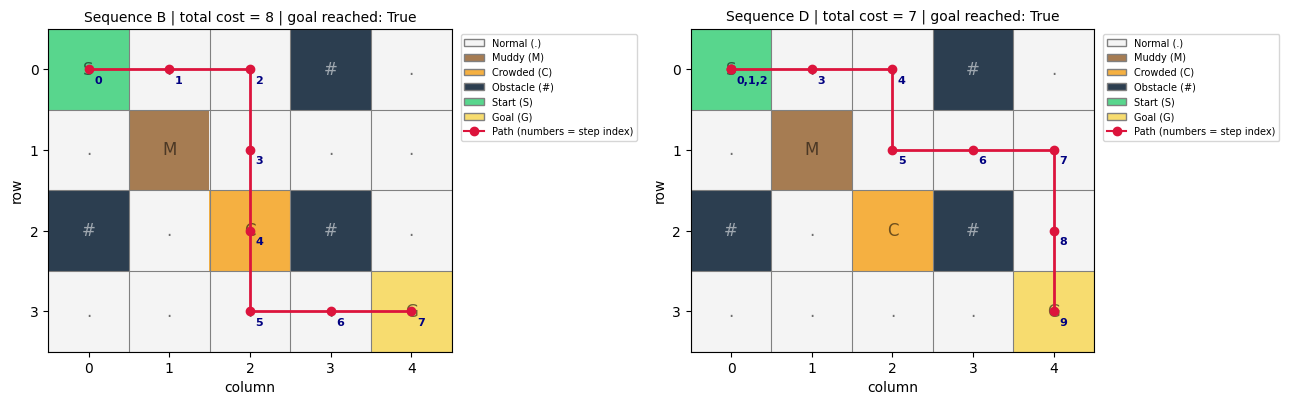

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, name in zip(axes, ['B', 'D']):
    res = results[name]
    plot_trajectory(GRID, res, f"Sequence {name} | total cost = {res['total_cost']} | goal reached: {res['goal_reached']}", ax=ax)
plt.tight_layout()
plt.show()

In [64]:
# Evidence for 7E: log entries of the unusual commands in C and D
for name in ['C', 'D']:
    unusual = [e for e in results[name]['log'] if e['status'] != 'MOVED']
    print(f'--- Sequence {name}: non-MOVED log entries ---')
    print(pd.DataFrame(unusual).to_string(index=False), '\n')

--- Sequence C: non-MOVED log entries ---
 step command from_position to_position           status  step_cost  cumulative_cost
    1   NORTH        (0, 0)      (0, 0) BLOCKED_BOUNDARY          0                0
    4    EAST        (0, 2)      (0, 2) BLOCKED_OBSTACLE          0                2
    6    JUMP        (1, 2)      (1, 2)  UNKNOWN_COMMAND          0                3 

--- Sequence D: non-MOVED log entries ---
 step command from_position to_position           status  step_cost  cumulative_cost
    1    WAIT        (0, 0)      (0, 0)           WAITED          0                0
    2   NORTH        (0, 0)      (0, 0) BLOCKED_BOUNDARY          0                0 



**7E - Answers (based on my actual output above)**

1. **Why do A and B differ in cost despite 7 valid moves each?** A costs 9 and B costs 8. Both make 7 successful moves and both end at G, but the *cells they enter* differ. A goes `SOUTH` then `EAST` into (1, 1), the muddy cell `M`, which costs 3 on its own. B passes through (2, 2), the crowded cell `C`, which costs 2. Every other cell entered costs 1 in both. So A = 6x1 + 3 = 9 and B = 6x1 + 2 = 8: cost depends on the **sequence of positions**, not only the count of moves.

2. **How were unusual commands handled in C and D?**
   * Sequence C, step 1: `NORTH` from (0, 0) -> `BLOCKED_BOUNDARY`, position stays (0, 0), step cost 0, cumulative 0.
   * Sequence C, step 4: the third `EAST` from (0, 2) -> `BLOCKED_OBSTACLE` because (0, 3) is `#`, position stays (0, 2), cost 0, cumulative stays 2.
   * Sequence C, step 6: `JUMP` from (1, 2) -> `UNKNOWN_COMMAND`, position stays, cost 0, and `unknown_commands` becomes 1.
   * Sequence D, step 1: `WAIT` -> `WAITED`, position (0, 0), cost 0, `waits` = 1; step 2: `NORTH` -> `BLOCKED_BOUNDARY`, cost 0.
   In every case the history still received a new entry (the same cell repeated), and exactly one counter was increased.

3. **Why can a trajectory plot hide WAIT, blocked and unknown commands?** The plot draws a line between *different* cells. When the robot stays put, the new history point sits exactly on the previous one, so no visible segment appears; the plot cannot show *why* the robot stayed (wait, wall, obstacle or bad command) or that time was spent. That is why I label step indices on each cell (e.g. "0,1,2" on one cell reveals repeated positions) and why the **log** is still needed.

4. **Which of A-D for minimum terrain cost?** **Sequence D**, with total cost 7 (A = 9, B = 8, C = 8). Limitation: this is only the best of **four manually written** sequences. There may be an even cheaper sequence I did not think of, and I did not search all possibilities; comparing a few hand-picked examples cannot prove optimality. Systematically finding the cheapest route requires a search algorithm, which is Assignment 2.

## Task 8 - Test, explain, and make the notebook reproducible
### 8.1 Assertions (more than 12, covering all eight required categories)
Tests finish **silently** when correct, and a final line prints the pass message.

In [65]:
# 1) robot ID: valid and invalid
assert validate_robot_id('RB-104') is True
assert validate_robot_id(' rb-104 ') is True
assert validate_robot_id('RB-1045') is False
assert validate_robot_id('RB-10A') is False

# 2) clean_commands: supplied example and empty string
assert clean_commands(' south, EAST, , wait, jump, north ') == ['SOUTH', 'EAST', 'WAIT', 'JUMP', 'NORTH']
assert clean_commands('') == []
assert clean_commands(' , , ') == []

# 3) command_summary
s = command_summary(['EAST', 'EAST', 'WAIT', 'JUMP'])
assert s['total_commands'] == 4 and s['known_commands'] == 3 and s['unknown_commands'] == 1
assert s['movement_commands'] == 2 and s['wait_commands'] == 1
assert s['frequencies'] == {'EAST': 2, 'WAIT': 1, 'JUMP': 1}
assert s['unique_commands'] == {'EAST', 'WAIT', 'JUMP'}

# 4) mission_ready at the battery boundaries
assert mission_ready(25, True, ['EAST']) is True
assert mission_ready(24, True, ['EAST']) is False
assert mission_ready(100, True, ['EAST']) is True
assert mission_ready(101, True, ['EAST']) is False
assert mission_ready(80, False, ['EAST']) is False
assert mission_ready(80, True, []) is False

# 5) grid validation: valid grid + several invalid cases
assert validate_grid(GRID) == {'valid': True, 'errors': []}
assert validate_grid(grid_missing_goal)['errors'] == ['GOAL_COUNT']
assert validate_grid(grid_two_starts)['errors'] == ['START_COUNT']
assert validate_grid(grid_unequal)['errors'] == ['NON_RECTANGULAR']
assert validate_grid(grid_bad_symbol)['errors'] == ['INVALID_SYMBOL']
assert validate_grid(grid_empty)['errors'] == ['EMPTY_GRID']
assert find_symbol(GRID, 'S') == (0, 0) and find_symbol(GRID, 'G') == (3, 4)
assert find_symbol(GRID, '#') is None            # appears more than once

# 6) inside_grid: valid, negative, beyond last row/column
assert inside_grid(GRID, (3, 4)) is True
assert inside_grid(GRID, (-1, 0)) is False
assert inside_grid(GRID, (0, -1)) is False
assert inside_grid(GRID, (4, 0)) is False
assert inside_grid(GRID, (0, 5)) is False

# 7) move_once: every status
assert move_once(GRID, (0, 0), 'EAST')  == {'new_position': (0, 1), 'status': 'MOVED', 'step_cost': 1}
assert move_once(GRID, (1, 0), 'EAST')  == {'new_position': (1, 1), 'status': 'MOVED', 'step_cost': 3}   # mud
assert move_once(GRID, (1, 2), 'SOUTH') == {'new_position': (2, 2), 'status': 'MOVED', 'step_cost': 2}   # crowd
assert move_once(GRID, (1, 1), 'WAIT')  == {'new_position': (1, 1), 'status': 'WAITED', 'step_cost': 0}
assert move_once(GRID, (0, 0), 'NORTH') == {'new_position': (0, 0), 'status': 'BLOCKED_BOUNDARY', 'step_cost': 0}
assert move_once(GRID, (0, 2), 'EAST')  == {'new_position': (0, 2), 'status': 'BLOCKED_OBSTACLE', 'step_cost': 0}
assert move_once(GRID, (1, 1), 'JUMP')  == {'new_position': (1, 1), 'status': 'UNKNOWN_COMMAND', 'step_cost': 0}

# 8) full simulations with expected totals
assert results['A']['goal_reached'] and results['A']['total_cost'] == 9 and results['A']['final_position'] == (3, 4)
assert results['B']['goal_reached'] and results['B']['total_cost'] == 8 and results['B']['valid_moves'] == 7
assert (results['C']['valid_moves'], results['C']['blocked_moves'], results['C']['unknown_commands']) == (7, 2, 1)
assert results['C']['total_cost'] == 8
assert results['D']['goal_reached'] and results['D']['waits'] >= 1 and results['D']['blocked_moves'] >= 1

# extras: stop at goal, history rule, invalid inputs, GRID not modified, unseen grid
long_run = simulate_commands(GRID, SEQUENCE_B + ['NORTH', 'NORTH'], 'RB-104')
assert long_run['commands_received'] == 9 and long_run['commands_processed'] == 7      # stopped at goal
assert len(results['C']['history']) == results['C']['commands_processed'] + 1          # start + one per command
assert simulate_commands(grid_missing_goal, ['EAST'], 'RB-104')['simulation_status'] == 'INVALID_GRID'
assert simulate_commands(GRID, ['EAST'], 'RB104')['simulation_status'] == 'INVALID_ROBOT_ID'
assert GRID[0][0] == 'S' and GRID[3][4] == 'G'                                          # map never rewritten

OTHER_GRID = [['.', '.', 'G'],
              ['S', 'M', '.']]                                                          # different size/start/goal
other = simulate_commands(OTHER_GRID, ['NORTH', 'EAST', 'EAST'], 'rb-007')
assert other['goal_reached'] and other['start_position'] == (1, 0) and other['total_cost'] == 3
assert other['robot_id'] == 'RB-007'

print('All required tests: PASS')

All required tests: PASS


### 8.2 Reflection questions
**R1 - Why is a tuple better than a list for a coordinate?**
A coordinate is a fixed pair `(row, column)`; it should not be changed in place by accident. Tuples are immutable and **hashable**, so they can be stored in a `set` (as in `unique_positions`) or used as dictionary keys. A list is mutable and unhashable, so `{[0, 1]}` raises an error and a position could be silently altered.

**R2 - Where is a set useful and what operation does it make convenient?**
Sets are used in `ALLOWED_SYMBOLS` and `RECOGNISED_COMMANDS` (fast **membership tests** such as `cell in ALLOWED_SYMBOLS`), in `unique_commands`, in `unique_positions` (automatic **removal of duplicates**, so `len(...)` gives distinct cells visited), and in `validate_grid` where `len({len(row) for row in grid}) > 1` detects unequal row lengths.

**R3 - Why is a dictionary appropriate for `MOVE_DELTAS`, `TERRAIN_COSTS` and each log entry?**
In `MOVE_DELTAS` and `TERRAIN_COSTS` the program must go from a *name* (command or symbol) to a *value* (movement tuple or cost): a dictionary does that lookup directly and replaces long `if/elif` chains, and new commands/terrains are added by adding one entry. A log entry has several differently-typed named fields (`step`, `command`, `status`, ...); a dictionary lets us read `entry['status']` by meaning instead of remembering that "index 4 is the status".

### Connection to Assignment 2
We now have the **state** (position tuple), **actions** (commands), **transition rule** (`move_once`), **goal test** (position == G) and **path cost** (cumulative terrain cost). Search will only need to *choose* the commands automatically.

### AI-assistance disclosure
 *"I used Claude (Anthropic) to help draft and explain the solution. I read each function, ran every cell, tested it on my own inputs, and I can explain the code. The Sequence D design and the written answers were checked against my own outputs."*

In [66]:
# Reproducibility check: two independent runs give identical results (no randomness, no hidden state)
again = {name: simulate_commands(GRID, seq, 'RB-104') for name, seq in SEQUENCES.items()}
assert again == results
print('Reproducibility check: PASS  (now use Restart session -> Run all to confirm in a fresh runtime)')

Reproducibility check: PASS  (now use Restart session -> Run all to confirm in a fresh runtime)
